# Load libraries

In [92]:
import h5py
import pandas as pd
import numpy as np
import torch
import math
import matplotlib.pyplot as plt

# Read the inputs.

In [93]:
from numpy.lib import recfunctions as rfn

data_file = h5py.File('../../H5Files/M_inference.h5')
#data_file = h5py.File('../../H5Files/S_I_BG_ManyCouplings.h5')
labels_dataset = data_file['LABELS']['CLASS']
signal_indices = np.argwhere(labels_dataset[:] == 1)
background_indices = np.argwhere(labels_dataset[:] == 0)
print('BG events = ',len(background_indices))
print('Signal events = ',len(signal_indices))

couplings_array = data_file['INPUTS']['EVENT_GLOBAL']['hmass'][:]
print('Couplings shape = ',couplings_array.shape)

coupling_values = [0, 600, 700, 800, 900, 1000, 650, 870]
indices_per_coupling = {}
for coupling in coupling_values:
    indices = np.argwhere(abs(couplings_array[:] - coupling) < 1e-3)
    indices_per_coupling[coupling] = indices
    print(f'Coupling {coupling}: {len(indices)} events')


BG events =  3981348
Signal events =  5409875
Couplings shape =  (9391223,)
Coupling 0: 3981348 events
Coupling 600: 769172 events
Coupling 700: 798278 events
Coupling 800: 782714 events
Coupling 900: 760119 events
Coupling 1000: 736362 events
Coupling 650: 796017 events
Coupling 870: 767213 events


In [94]:
def compare_distributions(variable, weights, indices_dictionary, x_range=[0,100], variable_name='',n_bins=40):

        plt.figure(figsize=(10, 6),dpi=100)


        for coupling, indices in indices_dictionary.items():
            data = variable[indices]
            plt.hist(data, weights=weights[indices], bins=n_bins, histtype='step', label=f'Coupling {coupling}', density=True, range=x_range)

        plt.xlabel(variable_name)
        plt.xlim(x_range[0],x_range[1])
        plt.ylabel('Density')
        plt.title(f'Distribution of {variable_name}')
        plt.legend()
        # plt.yscale('log')
        plt.show()

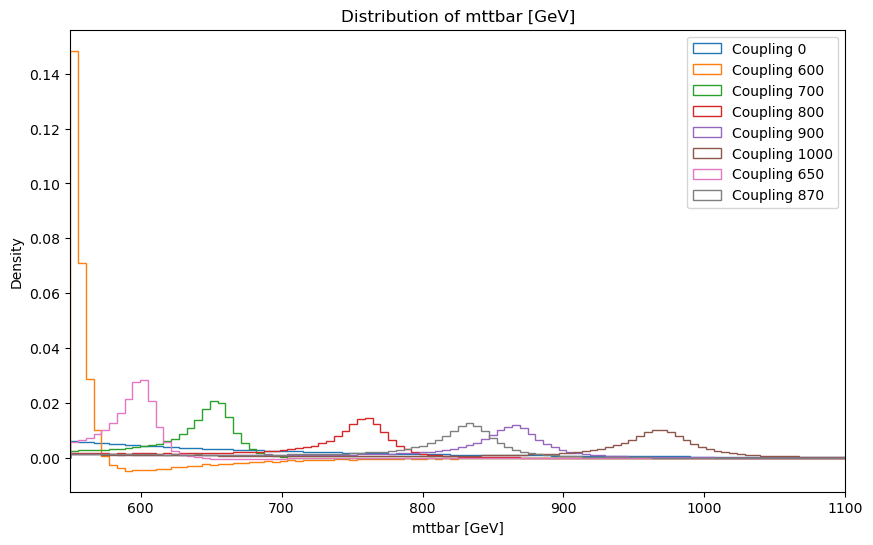

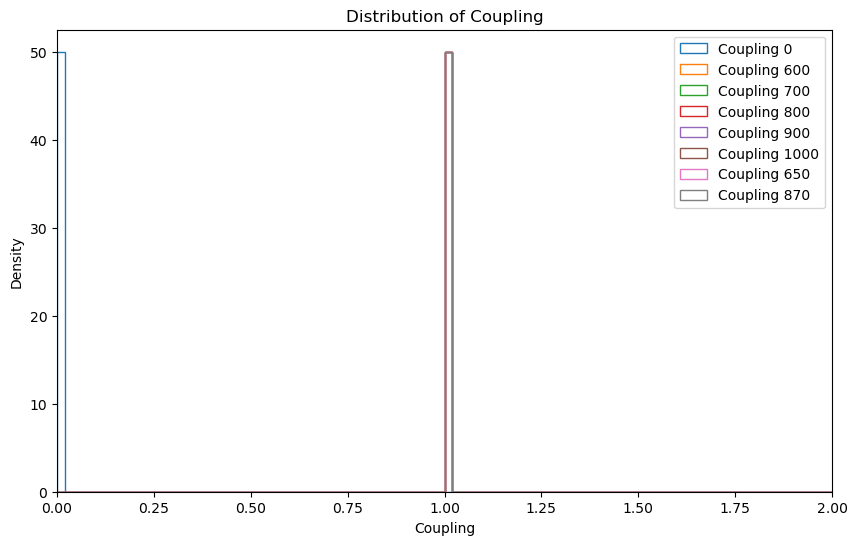

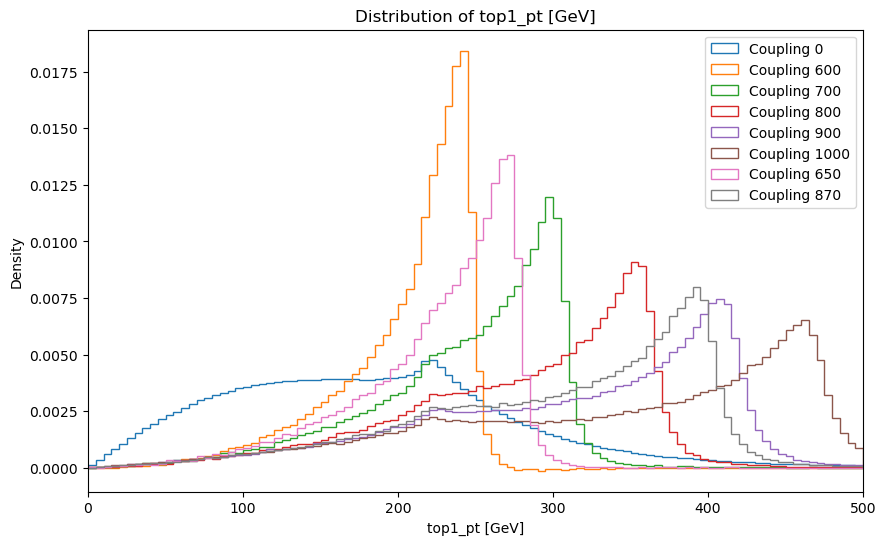

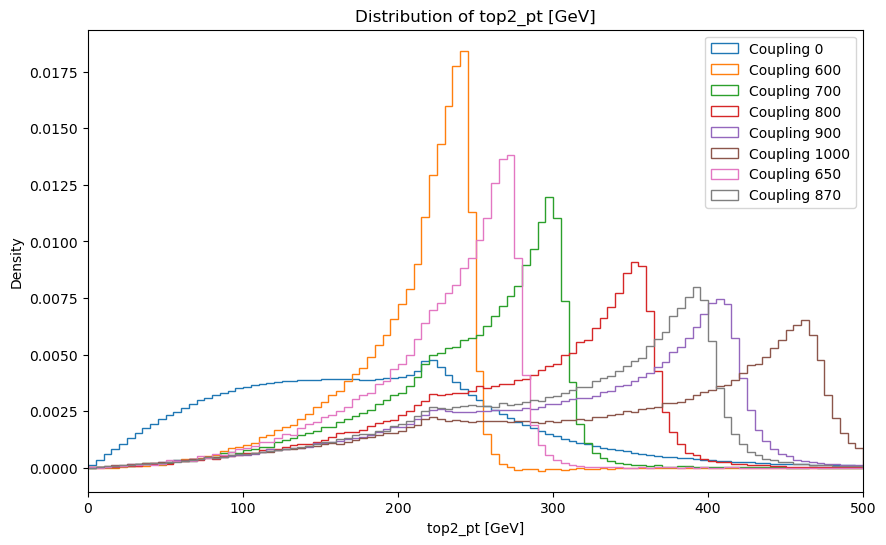

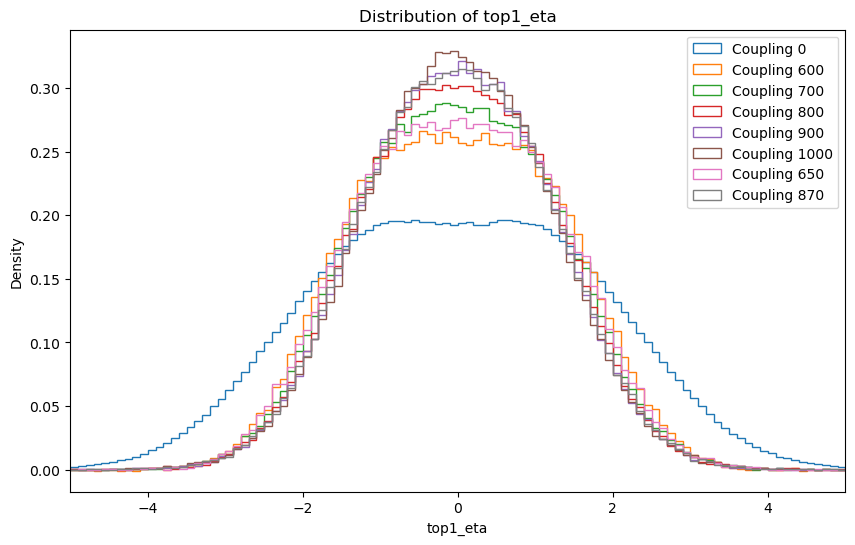

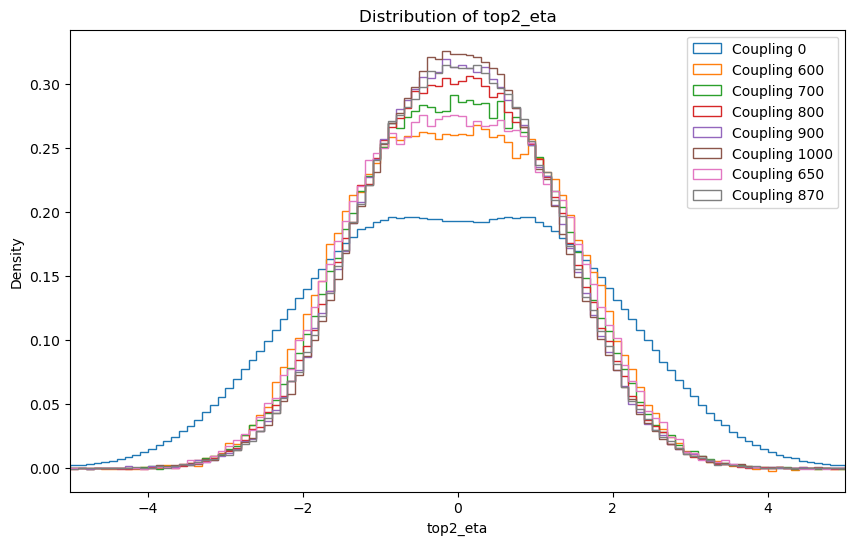

In [95]:
###### 
compare_distributions(data_file['INPUTS']['EVENT_GLOBAL']['mttbar'][:], data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], indices_per_coupling, x_range=[550,1100], variable_name='mttbar [GeV]', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_GLOBAL']['coupling'][:], data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], indices_per_coupling, x_range=[0,2], variable_name='Coupling', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top1_pt'][:], data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], indices_per_coupling, x_range=[0,500], variable_name='top1_pt [GeV]', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top2_pt'][:], data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], indices_per_coupling, x_range=[0,500], variable_name='top2_pt [GeV]', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top1_eta'][:], data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], indices_per_coupling, x_range=[-5,5], variable_name='top1_eta', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top2_eta'][:], data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], indices_per_coupling, x_range=[-5,5], variable_name='top2_eta', n_bins=100)

In [96]:
X, y = data_file['INPUTS']['EVENT_PARTICLES'][:], labels_dataset[:]
X = rfn.structured_to_unstructured(X)
X_mttbar = data_file['INPUTS']['EVENT_GLOBAL']['mttbar'][:]
X_couplings = data_file['INPUTS']['EVENT_GLOBAL']['hmass'][:]
X_weights = data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:]
X_weights[np.argwhere(X_couplings != 0)]  = X_weights[np.argwhere(X_couplings != 0)] / 7500
coupling_values_for_training = [600, 700, 800, 900, 1000]
X_couplings[background_indices] = np.random.choice(coupling_values_for_training, size=(len(background_indices),1))
y_category = np.empty_like(y)
couplings_category_dict = {}
for i in range(len(coupling_values)):
    coupling = coupling_values[i]
    indices = indices_per_coupling[coupling]
    y_category[indices] = i
    couplings_category_dict[coupling_values[i]] = i

# Form the data
X = np.concatenate([X, X_mttbar.reshape(-1, 1), X_couplings.reshape(-1, 1), X_weights.reshape(-1,1)], axis=1)
y = np.concatenate([y.reshape(-1, 1), y_category.reshape(-1, 1)], axis=1)

print('X shape = ',X.shape)
print('X example = ',X[1])
print('y shape = ',y.shape)
print('y example = ',y[1])

X shape =  (9391223, 9)
X example =  [ 3.1026572e+02 -3.6073989e-01  1.6518503e+00  3.1026572e+02
  7.8816140e-01 -1.4897423e+00  7.6620612e+02  8.0000000e+02
  1.3333333e-04]
y shape =  (9391223, 2)
y example =  [1. 3.]


In [97]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cuda device


In [98]:
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin

class LogScaler(BaseEstimator, TransformerMixin):
    def __init__(self, offset=1e-3, add_mask = False):
        self.offset = offset
        self.add_mask = add_mask

    def fit(self, X, y=None):
        return self  # no fitting needed

    def transform(self, X):
        log = np.log(X + self.offset)
        # Create a mask for nan values
        mask = np.isnan(log)
        if self.add_mask:
            return np.hstack([mask, log])
        return log

class PhiTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        sin_phi = np.sin(X)
        cos_phi = np.cos(X)
        return np.hstack([sin_phi, cos_phi])


from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler


scaler = ColumnTransformer(
    [('pt',LogScaler(), [0,3]),
    ('eta',StandardScaler(), [1,4]),
    # ('phi', PhiTransformer(), [2,5]),
    ('mttbar', LogScaler(), [6]),
    ('hmass', MinMaxScaler(), [7]),
    ('weights', 'passthrough', [8])
    ],
    remainder='drop'
)

X = scaler.fit_transform(X)
print("X shape after scaling = ", X.shape)
print("X example after scaling = ", X[1])

X shape after scaling =  (9391223, 7)
X example after scaling =  [ 5.7374325e+00  5.7374325e+00 -2.2732171e-01  4.9791592e-01
  6.6414523e+00  5.0000000e-01  1.3333333e-04]


# Separate the datasets for new observations

In [99]:
# Print the dictionary to help user steer the code
for key, values in couplings_category_dict.items():
    print(key, ' --> ', values)

0  -->  0
600  -->  1
700  -->  2
800  -->  3
900  -->  4
1000  -->  5
650  -->  6
870  -->  7


In [100]:
coupling_0p5_indices = np.argwhere(y[:,1]==6)
coupling_1p1_indices = np.argwhere(y[:,1]==7)

X_inference_1 = X[coupling_0p5_indices]
X_inference_2 = X[coupling_1p1_indices]
y_inference_1 = y[coupling_0p5_indices]
y_inference_2 = y[coupling_1p1_indices]

# Remove these indices from the dataset
X = np.delete(X, np.concatenate((coupling_0p5_indices, coupling_1p1_indices)), axis=0)
y = np.delete(y, np.concatenate((coupling_0p5_indices, coupling_1p1_indices)), axis=0)

In [101]:
# Split in train, val, test
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedShuffleSplit
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
train_indices, test_indices = next(sss.split(X, y))

X_train, y_train = X[train_indices], y[train_indices]
X_temp, y_temp = X[test_indices], y[test_indices]
X_val, X_test, y_val, y_test     = train_test_split(X_temp, y_temp, test_size=0.5, shuffle=True)

print('Train set size = ', X_train.shape)
print('Validation set size = ', X_val.shape)
print('Test set size = ', X_test.shape)

Train set size =  (6262394, 7)
Validation set size =  (782799, 7)
Test set size =  (782800, 7)


In [102]:
# As tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_val_tensor   = torch.tensor(X_val, dtype=torch.float32)
X_test_tensor  = torch.tensor(X_test, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_val_tensor   = torch.tensor(y_val, dtype=torch.float32)
y_test_tensor  = torch.tensor(y_test, dtype=torch.float32)

In [103]:
from torch.utils.data import TensorDataset, DataLoader

def create_dataloaders(X_train_tensor, y_train_tensor, X_val_tensor, y_val_tensor, X_test_tensor, y_test_tensor, batch_size=1024, signal="positive", background="positive", weight_column_index=-1, label_column_index=0):
    # First check the signal and background types
    if signal not in ["positive", "negative"]:
        raise ValueError("Signal must be 'positive' or 'negative'")
    if background not in ["positive", "negative"]:
        raise ValueError("Background must be 'positive' or 'negative'")

    # Train dataset masks
    signal_mask = y_train_tensor[:, label_column_index] == 1
    background_mask = y_train_tensor[:, label_column_index] == 0

    if signal == "positive":
        signal_weight_mask = X_train_tensor[:, weight_column_index] >= 0
    else:
        signal_weight_mask = X_train_tensor[:, weight_column_index] < 0
    if background == "positive":
        background_weight_mask = X_train_tensor[:, weight_column_index] >= 0
    else:
        background_weight_mask = X_train_tensor[:, weight_column_index] < 0
    
    train_mask = (signal_mask & signal_weight_mask) | (background_mask & background_weight_mask)
    X_train = X_train_tensor[train_mask]
    y_train = y_train_tensor[train_mask]

    # Validation dataset masks
    signal_mask_val = y_val_tensor[:, label_column_index] == 1
    background_mask_val = y_val_tensor[:, label_column_index] == 0

    if signal == "positive":
        signal_weight_mask_val = X_val_tensor[:, weight_column_index] >= 0
    else:
        signal_weight_mask_val = X_val_tensor[:, weight_column_index] < 0
    if background == "positive":
        background_weight_mask_val = X_val_tensor[:, weight_column_index] >= 0
    else:
        background_weight_mask_val = X_val_tensor[:, weight_column_index] < 0

    val_mask = (signal_mask_val & signal_weight_mask_val) | (background_mask_val & background_weight_mask_val)
    X_val = X_val_tensor[val_mask]
    y_val = y_val_tensor[val_mask]

    # Test dataset masks
    signal_mask_test = y_test_tensor[:, label_column_index] == 1
    background_mask_test = y_test_tensor[:, label_column_index] == 0

    if signal == "positive":
        signal_weight_mask_test = X_test_tensor[:, weight_column_index] >= 0
    else:
        signal_weight_mask_test = X_test_tensor[:, weight_column_index] < 0
    if background == "positive":
        background_weight_mask_test = X_test_tensor[:, weight_column_index] >= 0
    else:
        background_weight_mask_test = X_test_tensor[:, weight_column_index] < 0

    test_mask = (signal_mask_test & signal_weight_mask_test) | (background_mask_test & background_weight_mask_test)
    X_test = X_test_tensor[test_mask]
    y_test = y_test_tensor[test_mask]


    # Form the datasets
    train_dataset = TensorDataset(X_train,
                                  y_train)
    val_dataset   = TensorDataset(X_val,
                                  y_val)
    test_dataset  = TensorDataset(X_test,
                                    y_test)

    # Create DataLoader objects for training, validation, and testing in batches
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=6, persistent_workers=True, drop_last=True)
    val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=6, persistent_workers=True, drop_last=True)
    test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=6)

    return train_loader, val_loader, test_loader

In [104]:
import torch.nn as nn
# Define the Classifier
class Classifier(nn.Module):
    def __init__(self, x_dim, theta_dim = 0, hidden_dim = 64):
        super(Classifier, self).__init__()
        self.theta_dim = theta_dim
        if self.theta_dim == 0:
            print("NN: Using non-parametric model.")
        else:
            print("NN: Using parametric model with theta dimension =", theta_dim)
        self.net = nn.Sequential(
            nn.Linear(x_dim + theta_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(p=0.05),
            nn.Linear(hidden_dim, hidden_dim//2),
            nn.BatchNorm1d(hidden_dim//2),
            nn.ReLU(),
            nn.Dropout(p=0.05),
            nn.Linear(hidden_dim//2, 1),
        )

    def forward(self, X):
        logits = self.net(X)
        return logits

In [105]:
# Training loop on mini-batches with loss stored for plotting
import time
def train(model, criterion, optimizer, scheduler, train_loader, val_loader, n_epochs=110, device='cpu'):
    start_time = time.time()
    train_losses = []
    val_losses = []
    
    model.to(device)
    
    for epoch in range(n_epochs):
        epoch_start_time = time.time()
        model.train()
        # run over batches of data
        running_loss = 0.0
        for inputs, targets in train_loader:
            optimizer.zero_grad()
            inputs_device = inputs.to(device)
            targets_device = targets[:,0].to(device)
            outputs = model(inputs_device[:,:-1])
            outputs = torch.sigmoid(outputs)
            # Weight according to number of S/B events
            n_signal = torch.sum(targets_device==1).item()
            n_background = torch.sum(targets_device==0).item()
            weights = torch.where(targets_device==1, torch.tensor(n_background/(n_signal+n_background), device=device), torch.tensor(n_signal/(n_signal+n_background), device=device))
    
            loss = criterion(outputs.squeeze(), targets_device) * weights
            loss = torch.sum(loss)/len(loss)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
    
        # compute avergae loss over all batches
        train_loss = running_loss / len(train_loader)
        train_losses.append(train_loss)
    
        # Validation step
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs_device = inputs.to(device)
                targets_device = targets[:,0].to(device)
                outputs = model(inputs_device[:,:-1])
                outputs = torch.sigmoid(outputs)
                # Weight according to number of S/B events
                n_signal = torch.sum(targets_device==1).item()
                n_background = torch.sum(targets_device==0).item()
                weights = torch.where(targets_device==1, torch.tensor(n_background/(n_signal+n_background), device=device), torch.tensor(n_signal/(n_signal+n_background), device=device))
                loss = criterion(outputs.squeeze(), targets_device) * weights
                loss = torch.sum(loss)/len(loss)
                val_loss += loss.item()
    
        val_loss /= len(val_loader)
        val_losses.append(val_loss)
        scheduler.step(val_loss)

        current_time = time.time()
        print(f"Total Time: {round(current_time - start_time,1)}s, Epoch Time: {round(current_time - epoch_start_time,2)}s")
        print(f"Learning rate: {scheduler.get_last_lr()[0]}")
        print(f"Epoch {epoch+1}/{n_epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

    # Plot loss function for training and validation sets
    plt.plot(train_losses, label='Train Loss', color='red')
    plt.plot(val_losses, label='Validation Loss', color='green')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Train Loss', 'Validation Loss'])
    plt.show()

In [106]:
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
model_pp = Classifier(x_dim = X.shape[1] - 1 - 1, theta_dim = 1, hidden_dim = 64)
criterion = nn.BCELoss(reduction='none')
optimizer_pp = optim.AdamW(model_pp.parameters(), lr=0.0002, weight_decay=1e-3)
scheduler_pp = ReduceLROnPlateau(optimizer_pp, "min", patience=5, factor=0.8)

train_loader_pp, val_loader_pp, test_loader_pp = create_dataloaders(X_train_tensor, y_train_tensor,
                                                                X_val_tensor, y_val_tensor,
                                                                X_test_tensor, y_test_tensor,
                                                                batch_size=2048,
                                                                signal="positive",
                                                                background="positive")

NN: Using parametric model with theta dimension = 1


In [ ]:
# Train pp model
train(model_pp, criterion, optimizer_pp, scheduler_pp, train_loader_pp, val_loader_pp, n_epochs=80, device=device)

Total Time: 15.9s, Epoch Time: 15.86s
Learning rate: 0.0002
Epoch 1/80, Train Loss: 0.2252, Val Loss: 0.2133


In [18]:
save_model = False
if save_model:
    print("Saving model...")
    torch.save(model_pp.state_dict(), 'pNN_mass_negative_W_PP.pth')

Saving model...


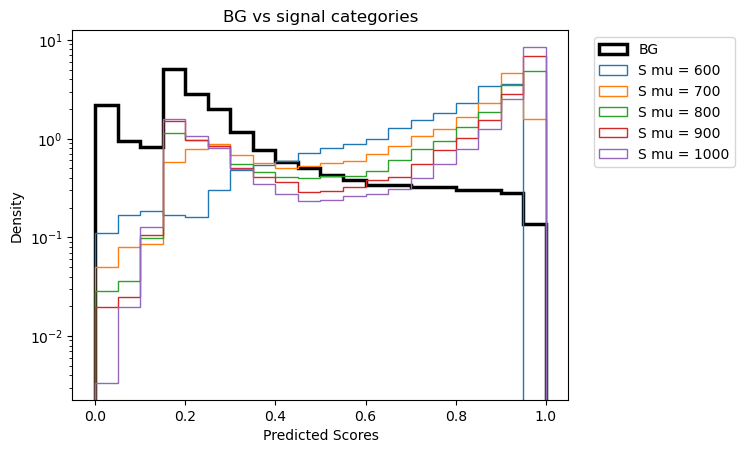

In [19]:
load_model = False
if load_model:
    eval_model = Classifier(x_dim = X.shape[1] - 1 - 1, theta_dim = 1, hidden_dim = 64)
    eval_model.load_state_dict(torch.load('pNN_mass_negative_W_PP.pth', weights_only=True))
else:
    eval_model = model_pp


eval_model.to('cpu')
eval_model.eval()

X_test_cpu = test_loader_pp.dataset.tensors[0].to('cpu')
y_test_cpu = test_loader_pp.dataset.tensors[1].to('cpu')

y_pred = torch.sigmoid(eval_model(X_test_cpu[:,:-1]).detach())

# Filter the predicted events for true Signal and true Background
sb_label = y_test_cpu[:,0]
category_label = y_test_cpu[:,1]
true_bkg = y_pred[sb_label==0].numpy()
training_categories = np.unique(category_label[sb_label==1])
training_categories = [int(cat) for cat in training_categories]

plt.hist(true_bkg, bins=20, histtype='step', label='Background', density=True, color='black', linewidth=2.5, range=[0,1])
plt.xlabel("Predicted Scores")
plt.ylabel("Density")
plt.title("BG vs signal categories")
#plt.xlim((0.7,0.9))
plt.yscale('log')
signal_legends = []
for icat in training_categories:
    # Plot the predicted scores for both true Signal and true Background events
    true_signal = y_pred[category_label==icat].numpy()
    plt.hist(true_signal, bins=20, histtype='step', label='Signal', density=True, range=[0,1])
    signal_legends.append(f"S mu = %s" % str(round(coupling_values[icat],2)))

plt.legend(["BG"]+signal_legends,bbox_to_anchor=(1.35, 1), loc='upper right')
plt.show()

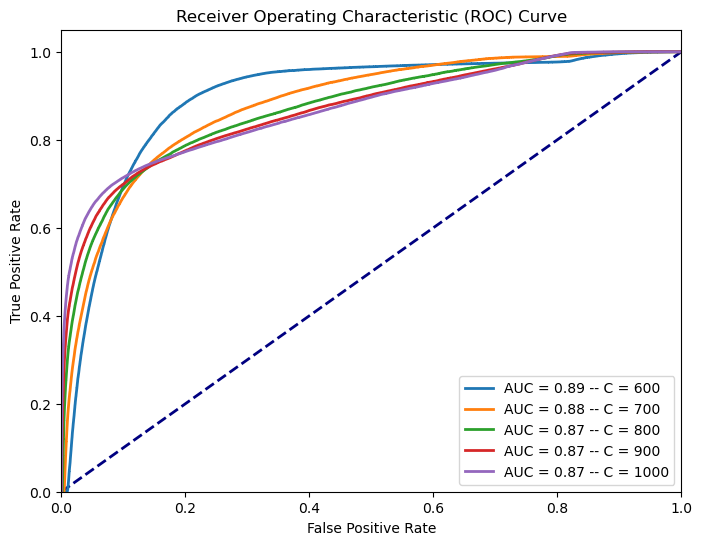

In [20]:
# Compute ROC curve
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')  # Random classifier line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')

for icat in training_categories:
    y_pred_cat = y_pred[(category_label==icat) | (category_label==0)].numpy()
    y_test_cat = y_test_cpu[(category_label==icat) | (category_label==0)]
    fpr, tpr, thresholds = roc_curve(y_test_cat[:,0], y_pred_cat)
    # Compute AUC (Area Under Curve)
    roc_auc = auc(fpr, tpr)
    # Plot ROC curve
    plt.plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc:.2f} -- C = {round(coupling_values[icat],2)}')
    
plt.legend(loc='lower right')
plt.show()

In [21]:
model_pn = Classifier(x_dim = X.shape[1] - 1 - 1, theta_dim = 1, hidden_dim = 64)
criterion = nn.BCELoss(reduction='none')
optimizer_pn = optim.AdamW(model_pn.parameters(), lr=0.0002, weight_decay=1e-3)
scheduler_pn = ReduceLROnPlateau(optimizer_pn, "min", patience=5, factor=0.8)

train_loader_pn, val_loader_pn, test_loader_pn = create_dataloaders(X_train_tensor, y_train_tensor,
                                                                X_val_tensor, y_val_tensor,
                                                                X_test_tensor, y_test_tensor,
                                                                batch_size=2048,
                                                                signal="negative",
                                                                background="positive")

NN: Using parametric model with theta dimension = 1


Total Time: 12.0s, Epoch Time: 11.99s
Learning rate: 0.0002
Epoch 1/110, Train Loss: 0.1241, Val Loss: 0.1084
Total Time: 23.0s, Epoch Time: 11.03s
Learning rate: 0.0002
Epoch 2/110, Train Loss: 0.1095, Val Loss: 0.1098
Total Time: 34.3s, Epoch Time: 11.28s
Learning rate: 0.0002
Epoch 3/110, Train Loss: 0.1088, Val Loss: 0.1084
Total Time: 45.3s, Epoch Time: 10.98s
Learning rate: 0.0002
Epoch 4/110, Train Loss: 0.1086, Val Loss: 0.1085
Total Time: 55.8s, Epoch Time: 10.56s
Learning rate: 0.0002
Epoch 5/110, Train Loss: 0.1084, Val Loss: 0.1067
Total Time: 65.8s, Epoch Time: 9.91s
Learning rate: 0.0002
Epoch 6/110, Train Loss: 0.1082, Val Loss: 0.1072
Total Time: 75.7s, Epoch Time: 9.94s
Learning rate: 0.0002
Epoch 7/110, Train Loss: 0.1081, Val Loss: 0.1077
Total Time: 86.1s, Epoch Time: 10.38s
Learning rate: 0.0002
Epoch 8/110, Train Loss: 0.1080, Val Loss: 0.1061
Total Time: 95.9s, Epoch Time: 9.77s
Learning rate: 0.0002
Epoch 9/110, Train Loss: 0.1079, Val Loss: 0.1065
Total Time: 1

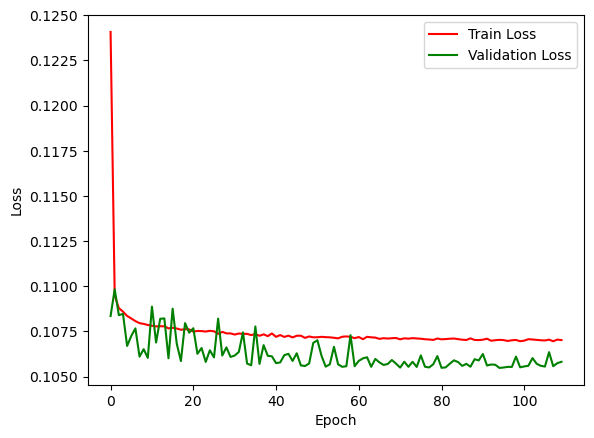

In [22]:
train(model_pn, criterion, optimizer_pn, scheduler_pn, train_loader_pn, val_loader_pn, n_epochs=110, device=device)

In [23]:
save_model = True
if save_model:
    print("Saving model...")
    torch.save(model_pn.state_dict(), 'pNN_mass_negative_W_PN.pth')

Saving model...


Doing category = 1
Doing category = 2
Doing category = 3
Doing category = 4
Doing category = 5


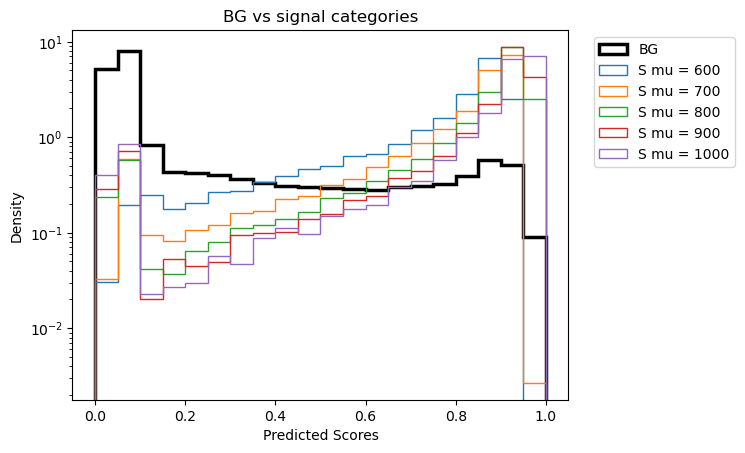

In [24]:
load_model = False
if load_model:
    eval_model = Classifier(x_dim = X.shape[1] - 1 -1, theta_dim = 1, hidden_dim = 64)
    eval_model.load_state_dict(torch.load('pNN_mass_negative_W_PN.pth', weights_only=True))
else:
    eval_model = model_pn


eval_model.to('cpu')
eval_model.eval()

X_test_cpu = test_loader_pn.dataset.tensors[0].to('cpu')
y_test_cpu = test_loader_pn.dataset.tensors[1].to('cpu')

y_pred = torch.sigmoid(eval_model(X_test_cpu[:,:-1]).detach())

# Filter the predicted events for true Signal and true Background
sb_label = y_test_cpu[:,0]
category_label = y_test_cpu[:,1]
true_bkg = y_pred[sb_label==0].numpy()
training_categories = np.unique(category_label[sb_label==1])
training_categories = [int(cat) for cat in training_categories]

plt.hist(true_bkg, bins=20, histtype='step', label='Background', density=True, color='black', linewidth=2.5, range=[0,1])
plt.xlabel("Predicted Scores")
plt.ylabel("Density")
plt.title("BG vs signal categories")
#plt.xlim((0.7,0.9))
plt.yscale('log')
signal_legends = []
for icat in training_categories:
    # Plot the predicted scores for both true Signal and true Background events
    print(f"Doing category = {icat}")
    true_signal = y_pred[category_label==icat].numpy()
    plt.hist(true_signal, bins=20, histtype='step', label='Signal', density=True, range=[0,1])
    signal_legends.append(f"S mu = %s" % str(round(coupling_values[icat],2)))

plt.legend(["BG"]+signal_legends,bbox_to_anchor=(1.35, 1), loc='upper right')
plt.show()

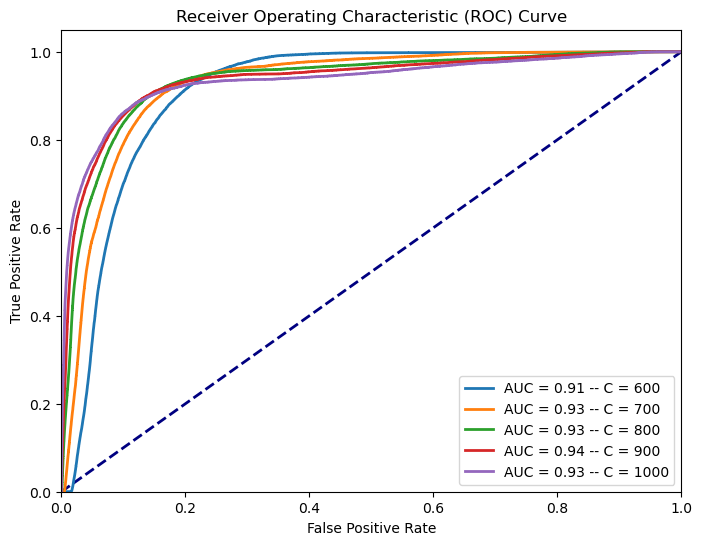

In [25]:
# Compute ROC curve
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')  # Random classifier line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')

for icat in training_categories:
    y_pred_cat = y_pred[(category_label==icat) | (category_label==0)].numpy()
    y_test_cat = y_test_cpu[(category_label==icat) | (category_label==0)]
    fpr, tpr, thresholds = roc_curve(y_test_cat[:,0], y_pred_cat)
    # Compute AUC (Area Under Curve)
    roc_auc = auc(fpr, tpr)
    # Plot ROC curve
    plt.plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc:.2f} -- C = {round(coupling_values[icat],2)}')
    
plt.legend(loc='lower right')
plt.show()

In [26]:
# Calculate the mixture coefficcients

# C(y) = Sum(wi for wi >0) / Sum(wi) with wi belonging to the "y" category

# First C0 -> This is one because the BG weights are all positive
bg_mask = y_train[:,0]==0
signal_mask = y_train[:,0]==1
C_zero = (X_train[bg_mask & (X_train[:,-1]>=0)][:,-1]).sum()/ X_train[bg_mask][:,-1].sum() 
print("C0 =", C_zero)

# Now C1
C_one = len(X_train[signal_mask & (X_train[:,-1]>=0)][:,-1])/ len(X_train[signal_mask][:,-1])
print("C1 =", C_one)

C0 = 1.0
C1 = 0.748624450657651


In [73]:
def ratio(x_obs, theta, model):
    X = torch.cat([x_obs, theta], dim=1)
    logits = model(X)
    s = torch.sigmoid(logits)
    r = s / (1 - s)
    return r

def log_likelihood(theta, X_obs, model_pp, model_pn, c0, c1):
    # X_obs: shape [N, x_dim]
    thetas = theta.unsqueeze(0).expand(len(X_obs), -1)
    r_pp = ratio(X_obs, thetas, model_pp)
    r_pn = ratio(X_obs, thetas, model_pn)
    r_vals = r_pp * c1/c0 + r_pn * (1-c1)/c0
    return torch.sum(torch.log(r_vals))

def find_uncertainty(llh_array, x_array):
    min_llh = np.min(llh_array)
    one_sigma_height = min_llh + 0.5*abs(min_llh)
    # Shift the LLH to have the zeroes at one_sigma_height
    llh_array = llh_array - one_sigma_height

    # Look for a sign change to look for the zeroes and store their index
    zero_indices = []
    for index in range(0,len(llh_array)-1):
        if (llh_array[index] * llh_array[index+1] < 0):
            zero_indices.append(index)
            
    # Get the coordinates from the indices
    one_sigma_uncertainties = x_array[zero_indices]
    return one_sigma_uncertainties


[[5.446106   5.446106   1.3026755  0.68346685 6.3869863  0.125
  1.        ]]


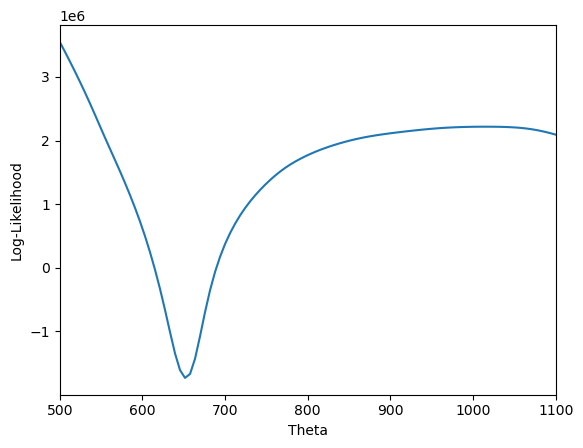

MLE estimate for theta: 651.5151515151515
[627.27272727 669.6969697 ]


In [75]:
new_data =  X_inference_1
print(new_data[0])
new_data = new_data.reshape(-1, new_data.shape[2])
new_data = new_data[:,:-2] # Remove coupling and weeightcolumn
new_X = torch.tensor(new_data, requires_grad=False)


log_likelihoods = []
x = np.linspace(500,1100,100)
for ix in x:
    theta_transformed = scaler["hmass"].transform([[ix]])[0,0]
    theta_tensor = torch.tensor([theta_transformed], requires_grad=False, dtype=torch.float32)
    llh = -2*log_likelihood(theta_tensor, new_X, model_pp, model_pn, C_zero, C_one) # Evaluate using the ML model!
    log_likelihoods.append(llh.item())

plt.plot(x, log_likelihoods)
plt.xlabel("Theta")
plt.ylabel("Log-Likelihood")
plt.xlim((min(x),max(x)))
plt.show()

# Get the MLE estimate for theta
np.argmin(log_likelihoods)
theta_mle = x[np.argmin(log_likelihoods)]
print("MLE estimate for theta:", theta_mle)

print(find_uncertainty(log_likelihoods, x))

(767213, 1, 7)
[[ 5.8338027   5.8338027  -0.7501767  -0.08240927  6.713613    0.67499995
   1.        ]]
torch.Size([767213, 5])


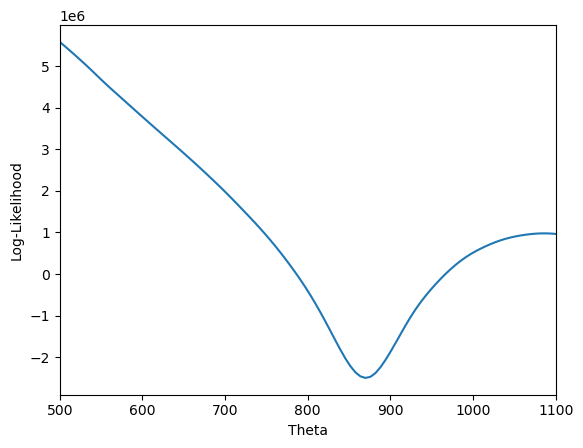

MLE estimate for theta: 869.6969696969697
[821.21212121 912.12121212]


In [76]:
new_data =  X_inference_2
print(new_data.shape)
print(new_data[0])
new_data = new_data.reshape(-1, new_data.shape[2])
new_data = new_data[:,:-2] # Remove coupling and weeightcolumn
new_X = torch.tensor(new_data, requires_grad=False)

print(new_X.shape)

log_likelihoods = []
x = np.linspace(500,1100,100)
for ix in x:
    theta_transformed = scaler["hmass"].transform([[ix]])[0,0]
    theta_tensor = torch.tensor([theta_transformed], requires_grad=False, dtype=torch.float32)
    llh = -2*log_likelihood(theta_tensor, new_X, model_pp, model_pn, C_zero, C_one) # Evaluate using the ML model!
    log_likelihoods.append(llh.item())

plt.plot(x, log_likelihoods)
plt.xlabel("Theta")
plt.ylabel("Log-Likelihood")
plt.xlim((min(x),max(x)))
plt.show()

# Get the MLE estimate for theta
np.argmin(log_likelihoods)
theta_mle = x[np.argmin(log_likelihoods)]
print("MLE estimate for theta:", theta_mle)

print(find_uncertainty(log_likelihoods, x))

(782800, 7)
(398168, 1, 7)
torch.Size([398168, 5])


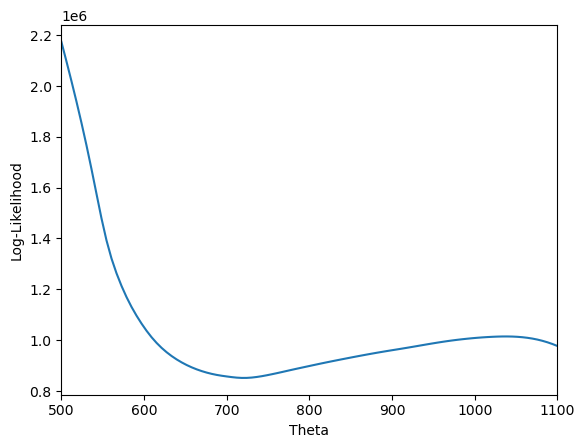

MLE estimate for theta: 718.1818181818182
[560.60606061]


In [91]:
new_data =  X_test
print(new_data.shape)
n_bg = len(np.argwhere(y_test[:,1]==0))
n_sg = len(np.argwhere(y_test[:,1]==1))
background_indices = np.concatenate((np.argwhere(y_test[:,1]==0),np.argwhere(y_test[:,1]==1)[:60]))

new_data = new_data[background_indices]
print(new_data.shape)

new_data = new_data.reshape(-1, new_data.shape[2])
new_data = new_data[:,:-2] # Remove coupling and weeightcolumn
new_X = torch.tensor(new_data, requires_grad=False)

print(new_X.shape)

log_likelihoods = []
x = np.linspace(500,1100,100)
for ix in x:
    theta_transformed = scaler["hmass"].transform([[ix]])[0,0]
    theta_tensor = torch.tensor([theta_transformed], requires_grad=False, dtype=torch.float32)
    llh = -2*log_likelihood(theta_tensor, new_X, model_pp, model_pn, C_zero, C_one) # Evaluate using the ML model!
    log_likelihoods.append(llh.item())

plt.plot(x, log_likelihoods)
plt.xlabel("Theta")
plt.ylabel("Log-Likelihood")
plt.xlim((min(x),max(x)))
plt.show()

# Get the MLE estimate for theta
np.argmin(log_likelihoods)
theta_mle = x[np.argmin(log_likelihoods)]
print("MLE estimate for theta:", theta_mle)

print(find_uncertainty(log_likelihoods, x))